In [1]:
# --- Importar bibliotecas principais ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configurar estilo visual
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Carregar o dataset
df = pd.read_csv("data/amazon_uk_products.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Aqui carregamos o mesmo dataset usado no Lab Bivariate.
Verifica se as colunas principais (category, price, stars, etc.) aparecem normalmente.

In [2]:
# --- Tabela de frequência por categoria ---
cat_freq = df['category'].value_counts()

# Mostrar top 5
print(cat_freq.head(5))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


Essa contagem mostra quais categorias têm mais produtos listados.

/var/folders/k3/c13ddj7d46n3kbwd2zx925mm0000gn/T/ipykernel_8835/3511095042.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, palette='viridis')


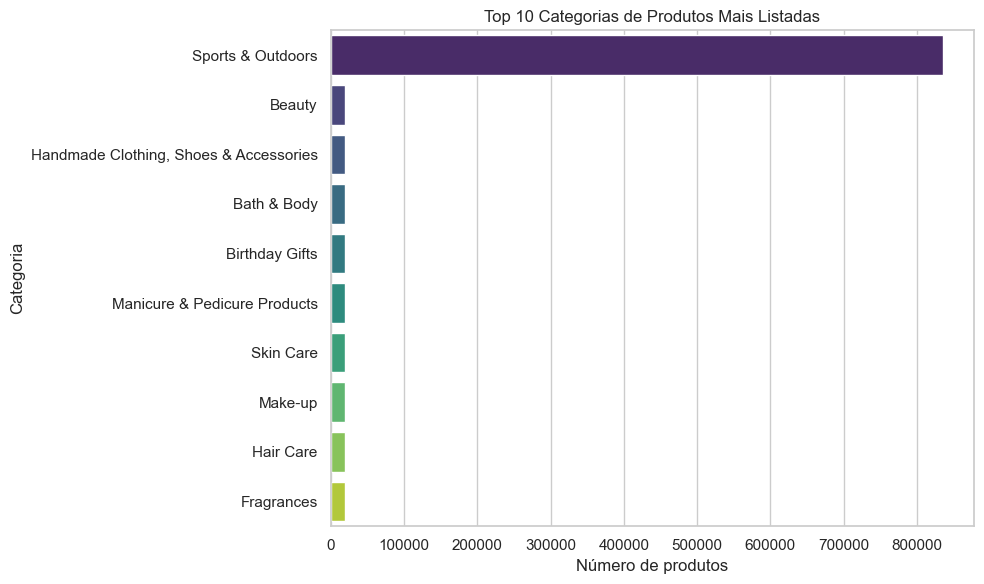

In [3]:
# --- Gráfico de barras das categorias mais comuns ---
top10 = cat_freq.head(10)

sns.barplot(x=top10.values, y=top10.index, palette='viridis')
plt.title("Top 10 Categorias de Produtos Mais Listadas")
plt.xlabel("Número de produtos")
plt.ylabel("Categoria")
plt.tight_layout()
plt.show()


O gráfico mostra as categorias mais populares no marketplace.


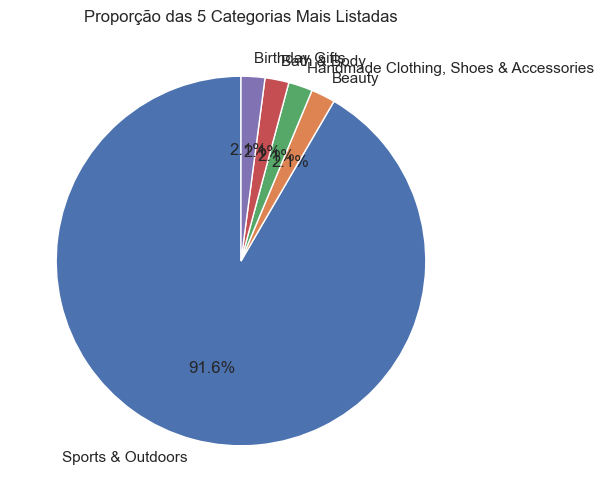

In [4]:
# --- Gráfico de pizza das 5 categorias principais ---
top5 = cat_freq.head(5)
plt.pie(top5, labels=top5.index, autopct='%1.1f%%', startangle=90)
plt.title("Proporção das 5 Categorias Mais Listadas")
plt.show()


O pie chart ajuda a ver se existe uma categoria dominante ou se há equilíbrio entre as mais populares.

The charts show that a few categories have many more listings than others.
It means that Amazon’s marketplace is concentrated — most sellers focus on specific product types.

In [5]:
# --- Calcular média, mediana e moda ---
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean: {mean_price:.2f}, Median: {median_price:.2f}, Mode: {mode_price:.2f}")

Mean: 89.24, Median: 19.09, Mode: 9.99


Essas três medidas ajudam a entender o “ponto médio” dos preços —
a média é influenciada por outliers,
a mediana mostra o ponto central real,
e a moda indica o preço mais comum.

In [6]:
# --- Calcular variância, desvio padrão, range e IQR ---
var_price = df['price'].var()
std_price = df['price'].std()
range_price = df['price'].max() - df['price'].min()
iqr_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Variance: {var_price:.2f}")
print(f"Standard deviation: {std_price:.2f}")
print(f"Range: {range_price:.2f}")
print(f"IQR: {iqr_price:.2f}")


Variance: 119445.49
Standard deviation: 345.61
Range: 100000.00
IQR: 36.00


Essas métricas mostram o quanto os preços variam -
um desvio padrão alto indica grande diversidade de valores.

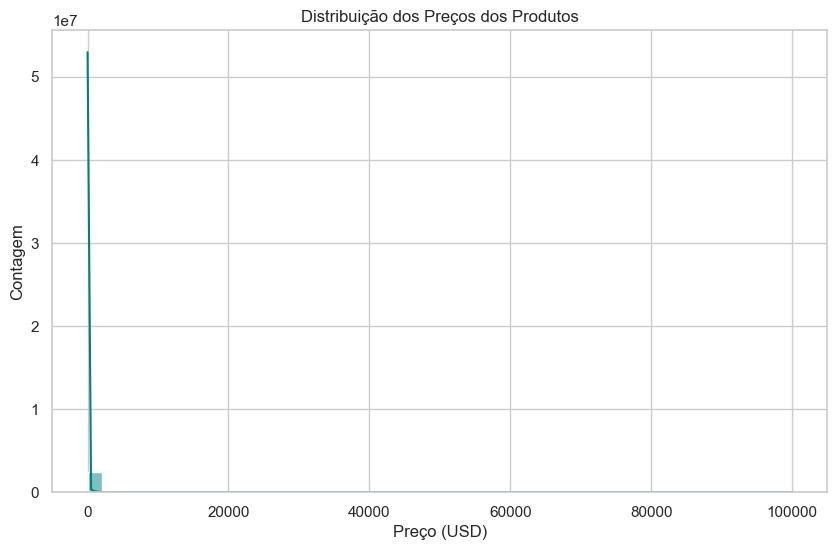

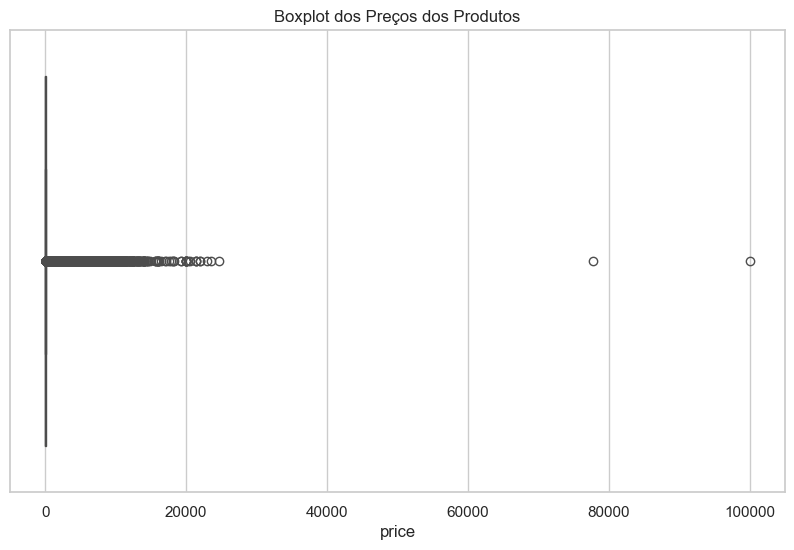

In [7]:
# --- Histograma de preços ---
sns.histplot(df['price'], bins=50, kde=True, color='teal')
plt.title("Distribuição dos Preços dos Produtos")
plt.xlabel("Preço (USD)")
plt.ylabel("Contagem")
plt.show()

# --- Boxplot para detectar outliers ---
sns.boxplot(x=df['price'], color='orange')
plt.title("Boxplot dos Preços dos Produtos")
plt.show()


O histograma mostra a forma da distribuição;
o boxplot revela se há produtos extremamente caros (outliers).

The price distribution is right-skewed, with many cheap products and a few very expensive ones.
That’s normal in online markets — most items are affordable, while a few luxury ones raise the maximum values.

In [10]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

print(f"Mean: {mean_rating:.2f}, Median: {median_rating:.2f}, Mode: {mode_rating:.2f}")

# Esses valores mostram a tendência geral da satisfação dos clientes.

Mean: 2.15, Median: 0.00, Mode: 0.00


In [14]:
# --- Variância e desvio padrão ---
var_rating = df['stars'].var()
std_rating = df['stars'].std()
iqr_rating = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

# --- Assimetria (skewness) e curtose (kurtosis) ---
skewness = df['stars'].skew()
kurtosis = df['stars'].kurtosis()

print(f"Variance: {var_rating:.3f}, Std Dev: {std_rating:.3f}")
print(f"Skewness: {skewness:.3f}, Kurtosis: {kurtosis:.3f}")

# A skewness indica se os ratings estão concentrados mais em notas altas ou baixas;
# a kurtosis mostra se a distribuição é mais achatada ou mais pontuda.


Variance: 4.817, Std Dev: 2.195
Skewness: 0.081, Kurtosis: -1.926


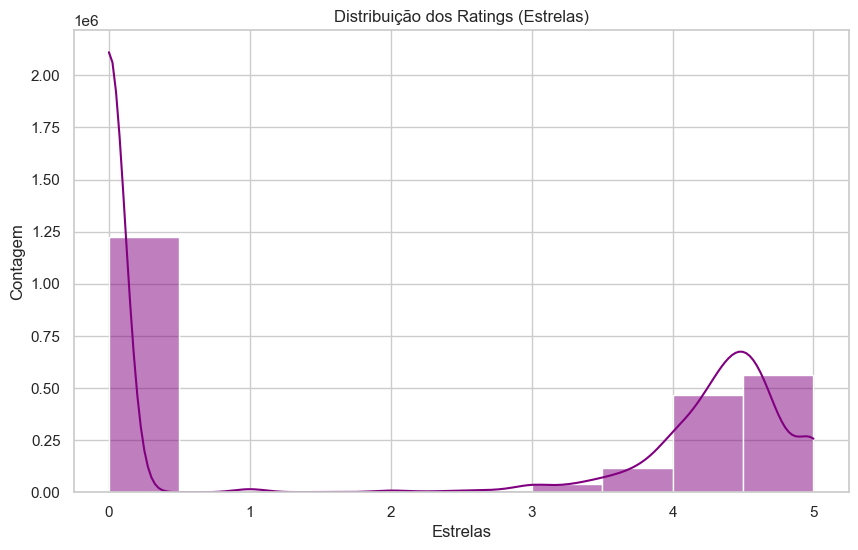

In [15]:
sns.histplot(df['stars'], bins=10, kde=True, color='purple')
plt.title("Distribuição dos Ratings (Estrelas)")
plt.xlabel("Estrelas")
plt.ylabel("Contagem")
plt.show()

# Um pico forte em 4–5 estrelas é esperado - produtos tendem a ter avaliações positivas.

Most ratings are very high, around 4 or 5 stars.
It means customers are generally happy with their purchases, or that people rate only when satisfied.
For a data analyst, this tells us that ratings are not evenly distributed, but biased towards positive values.